## Imports y funciones base

In [14]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "src"))
from train_model import (cargar_conjuntos, baseline_persistencia, baseline_media_movil, evaluar,
                         registrar_experimento, optimizar, entrenar_y_evaluar, guardar_seleccion)

SEED = 42

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
conjuntos, features = cargar_conjuntos()
train, val = conjuntos["train"], conjuntos["val"]   # test queda en conjuntos["test"]: se usa una sola vez, al final
X_train, y_train = train[features], train["target"]
X_val, y_val = val[features], val["target"]
print(f"{len(features)} features | X_train {X_train.shape} | X_val {X_val.shape}")

train: 849 días | 2020-07-01 -> 2022-10-27
val: 182 días | 2022-10-28 -> 2023-04-27
test: 182 días | 2023-04-28 -> 2023-10-26
37 features | X_train (849, 37) | X_val (182, 37)


## Creación de los baselines

**rellenar más despierto**

In [16]:
frio = "Consolidado EE | Frio (Kw)"
coincide = (val["target"].iloc[:-1].to_numpy() == val[frio].iloc[1:].to_numpy()).mean()
print(f"target[D] == Frío[D+1] en el {coincide:.1%} de los días de validación")

target[D] == Frío[D+1] en el 100.0% de los días de validación


In [17]:
predicciones_base = {
    "persistencia": baseline_persistencia(val),
    "media_movil_7": baseline_media_movil(val, previo=train),
}

resultados_base = {}
for nombre, pred in predicciones_base.items():
    metricas = evaluar(y_val, pred)
    registrar_experimento(nombre, "validacion", metricas, semilla=SEED)
    resultados_base[nombre] = metricas

pd.DataFrame(resultados_base).T.round({"mae": 0, "rmse": 0, "r2": 3})

,mae,rmse,r2
persistencia,2700.0,3360.0,0.246
media_movil_7,2455.0,3299.0,0.273


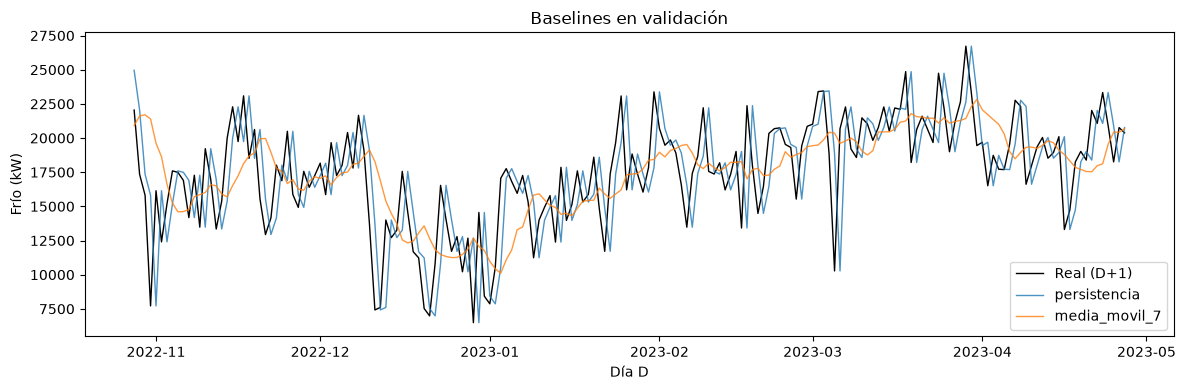

In [18]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(val["DIA"], y_val, label="Real (D+1)", color="black", linewidth=1)
for nombre, pred in predicciones_base.items():
    ax.plot(val["DIA"], pred, label=nombre, linewidth=1, alpha=0.8)
ax.set_xlabel("Día D")
ax.set_ylabel("Frío (kW)")
ax.set_title("Baselines en validación")
ax.legend()
plt.tight_layout()
plt.show()

## Experimentos

In [19]:
def espacio_ridge(trial):
    return {"alpha": trial.suggest_float("alpha", 1e-3, 1e5, log=True)}


def espacio_lasso(trial):
    return {"alpha": trial.suggest_float("alpha", 1, 1e4, log=True)}


def espacio_random_forest(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "max_depth": trial.suggest_int("max_depth", 2, 20),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 40),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.5, 1.0),
    }


def espacio_xgboost(trial):
    return {
        "objective": trial.suggest_categorical("objective", ["reg:squarederror", "reg:absoluteerror"]),
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 50, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "colsample_bylevel": trial.suggest_float("colsample_bylevel", 0.5, 1.0),
        "colsample_bynode": trial.suggest_float("colsample_bynode", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1e4, log=True),
    }


def espacio_lightgbm(trial):
    return {
        "objective": trial.suggest_categorical("objective", ["regression", "regression_l1"]),
        "n_estimators": trial.suggest_int("n_estimators", 100, 2000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 128, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "feature_fraction_bynode": trial.suggest_float("feature_fraction_bynode", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 100, log=True),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 1e4, log=True),
        "extra_trees": trial.suggest_categorical("extra_trees", [False, True]),
    }

In [20]:
for nombre, espacio in [("ridge", espacio_ridge), ("lasso", espacio_lasso),
                        ("random_forest", espacio_random_forest), ("xgboost", espacio_xgboost),
                        ("lightgbm", espacio_lightgbm)]:
    optimizar(nombre, espacio, X_train, y_train, n_trials=3, semilla=SEED, registrar=False)

ridge: 3 completos, 0 podados | MAE CV 3,059 ± 414 kW
lasso: 3 completos, 0 podados | MAE CV 2,947 ± 301 kW
random_forest: 3 completos, 0 podados | MAE CV 3,127 ± 233 kW
xgboost: 3 completos, 0 podados | MAE CV 3,079 ± 393 kW
lightgbm: 3 completos, 0 podados | MAE CV 3,174 ± 465 kW


In [ ]:
estudio_ridge = optimizar("ridge", espacio_ridge, X_train, y_train, n_trials=200, semilla=SEED)

ridge: 27 completos, 73 podados | MAE CV 2,944 ± 315 kW


In [ ]:
estudio_lasso = optimizar("lasso", espacio_lasso, X_train, y_train, n_trials=200, semilla=SEED)

lasso: 43 completos, 57 podados | MAE CV 2,935 ± 282 kW


In [ ]:
estudio_rf = optimizar("random_forest", espacio_random_forest, X_train, y_train,
                       n_trials=2000, timeout=int(1.5 * 3600), semilla=SEED)

random_forest: 160 completos, 1753 podados | MAE CV 3,072 ± 206 kW


In [ ]:
estudio_xgb = optimizar("xgboost", espacio_xgboost, X_train, y_train,
                        n_trials=1000, timeout=2 * 3600, semilla=SEED)

xgboost: 635 completos, 4365 podados | MAE CV 3,002 ± 360 kW


In [ ]:
estudio_lgbm = optimizar("lightgbm", espacio_lightgbm, X_train, y_train,
                         n_trials=1000, timeout=2 * 3600, semilla=SEED)

lightgbm: 455 completos, 3269 podados | MAE CV 3,003 ± 337 kW


In [26]:
estudios = {"ridge": estudio_ridge, "lasso": estudio_lasso, "random_forest": estudio_rf,
            "xgboost": estudio_xgb, "lightgbm": estudio_lgbm}
pd.DataFrame({n: {"mae_cv": e.best_value,
                  "desvio_folds": e.best_trial.user_attrs["mae_desvio_folds"],
                  "trials": len(e.trials),
                  "podados": sum(t.state.name == "PRUNED" for t in e.trials)}
              for n, e in estudios.items()}).T.round(0)

,mae_cv,desvio_folds,trials,podados
ridge,2944.0,315.0,100.0,73.0
lasso,2935.0,282.0,100.0,57.0
random_forest,3072.0,206.0,1913.0,1753.0
xgboost,3002.0,360.0,5000.0,4365.0
lightgbm,3003.0,337.0,3724.0,3269.0
